In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/dynamicpricing-data/dynamic_pricing.csv


In [2]:
df = pd.read_csv('/kaggle/input/dynamicpricing-data/dynamic_pricing.csv')

# Check the structure of the dataset
print("Shape of the dataset:", df.shape)
print("First few rows:")
print(df.head())

Shape of the dataset: (1000, 10)
First few rows:
   Number_of_Riders  Number_of_Drivers Location_Category  \
0                90                 45             Urban   
1                58                 39          Suburban   
2                42                 31             Rural   
3                89                 28             Rural   
4                78                 22             Rural   

  Customer_Loyalty_Status  Number_of_Past_Rides  Average_Ratings  \
0                  Silver                    13             4.47   
1                  Silver                    72             4.06   
2                  Silver                     0             3.99   
3                 Regular                    67             4.31   
4                 Regular                    74             3.77   

  Time_of_Booking Vehicle_Type  Expected_Ride_Duration  \
0           Night      Premium                      90   
1         Evening      Economy                      43   
2      

In [3]:
# Basic summary statistics
print("Summary Statistics:")
print(df.describe(include='all'))

Summary Statistics:
        Number_of_Riders  Number_of_Drivers Location_Category  \
count        1000.000000        1000.000000              1000   
unique               NaN                NaN                 3   
top                  NaN                NaN             Urban   
freq                 NaN                NaN               346   
mean           60.372000          27.076000               NaN   
std            23.701506          19.068346               NaN   
min            20.000000           5.000000               NaN   
25%            40.000000          11.000000               NaN   
50%            60.000000          22.000000               NaN   
75%            81.000000          38.000000               NaN   
max           100.000000          89.000000               NaN   

       Customer_Loyalty_Status  Number_of_Past_Rides  Average_Ratings  \
count                     1000           1000.000000      1000.000000   
unique                       3                   NaN 

Missing Values:
Number_of_Riders           0
Number_of_Drivers          0
Location_Category          0
Customer_Loyalty_Status    0
Number_of_Past_Rides       0
Average_Ratings            0
Time_of_Booking            0
Vehicle_Type               0
Expected_Ride_Duration     0
Historical_Cost_of_Ride    0
dtype: int64


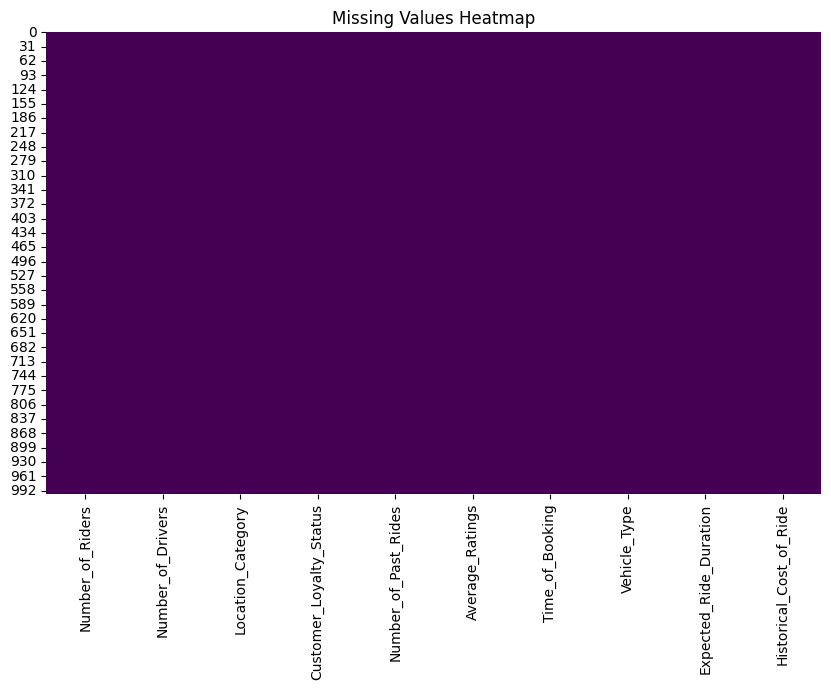

In [4]:
print("Missing Values:")
print(df.isnull().sum())

# Visualize missing data (requires seaborn)
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.heatmap(df.isnull(), cbar=False, cmap="viridis")
plt.title("Missing Values Heatmap")
plt.show()

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


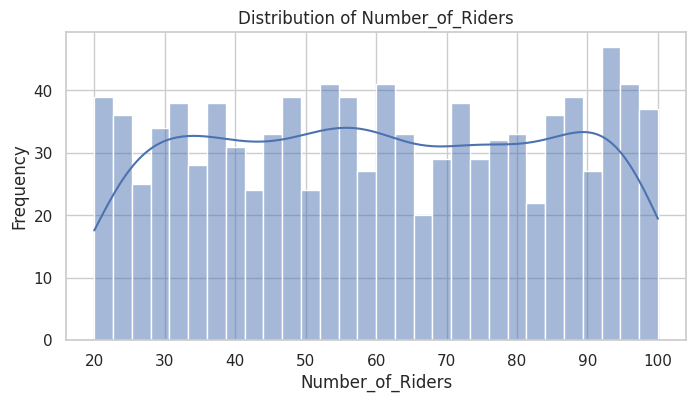

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


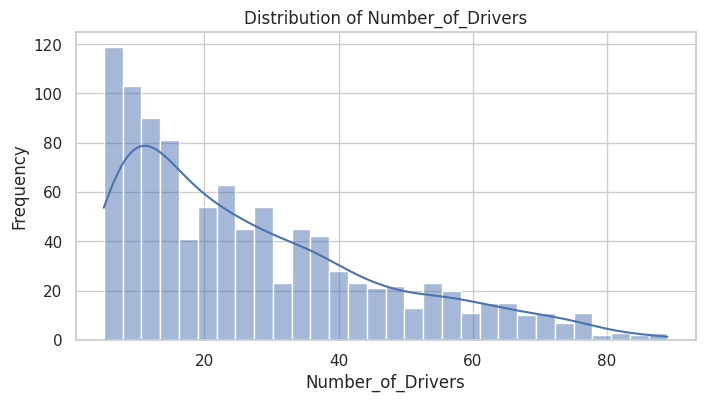

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


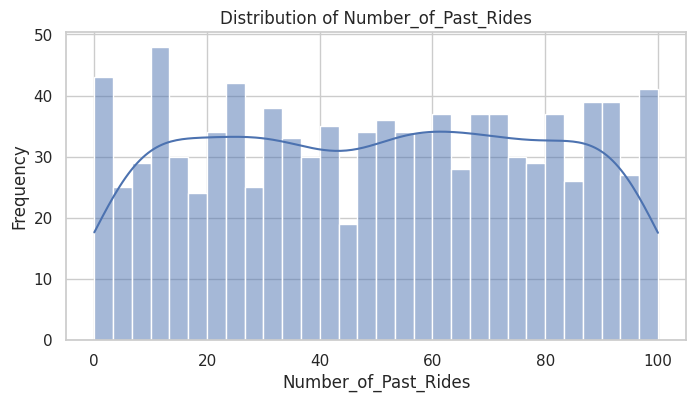

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


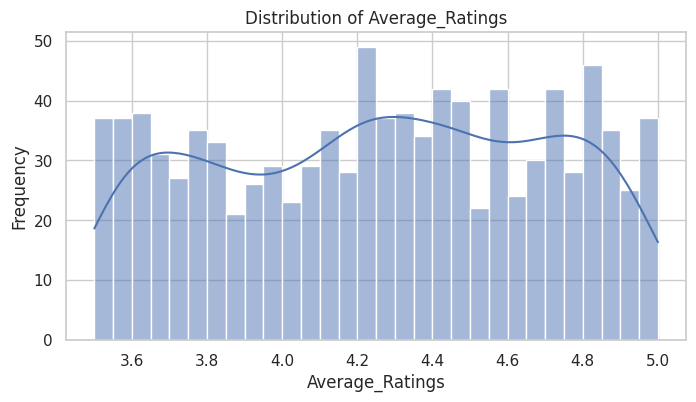

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


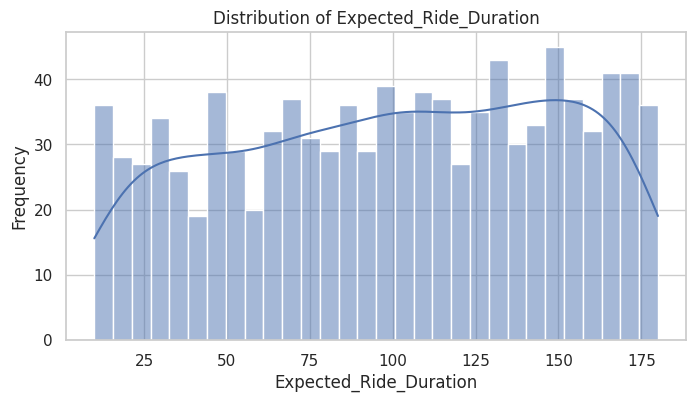

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


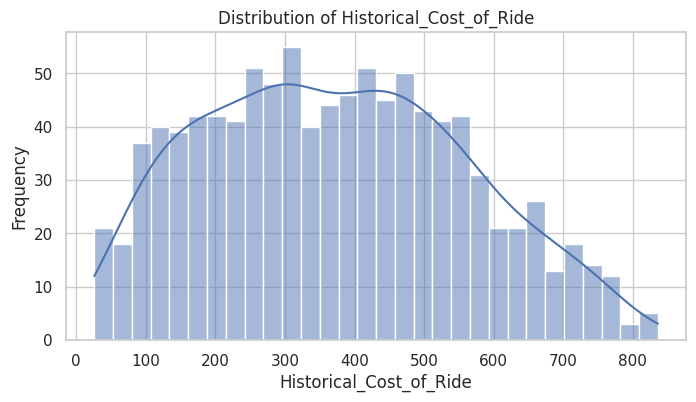

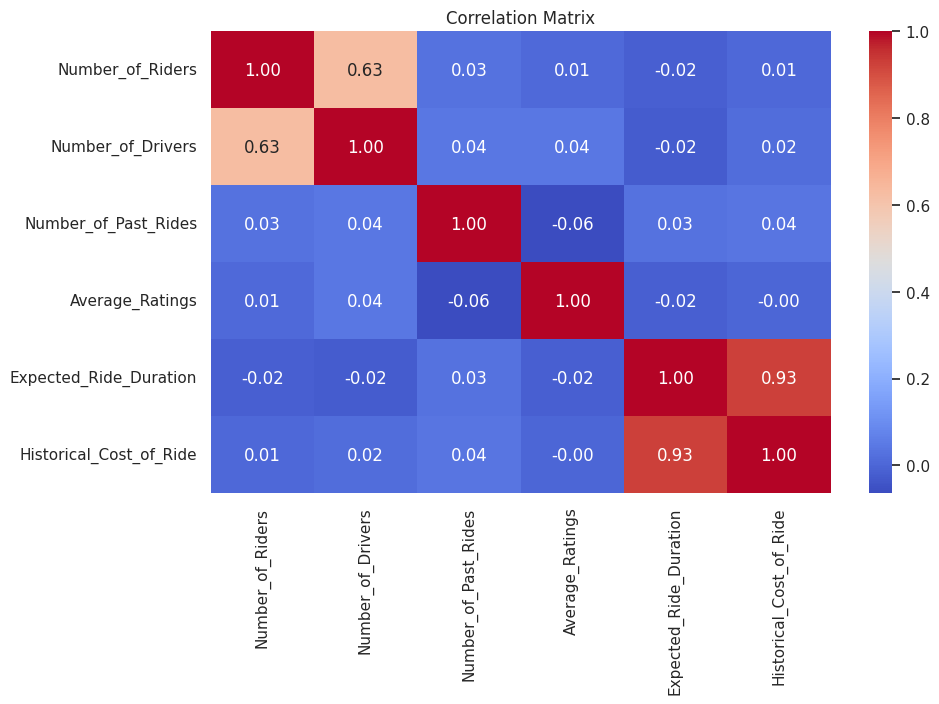

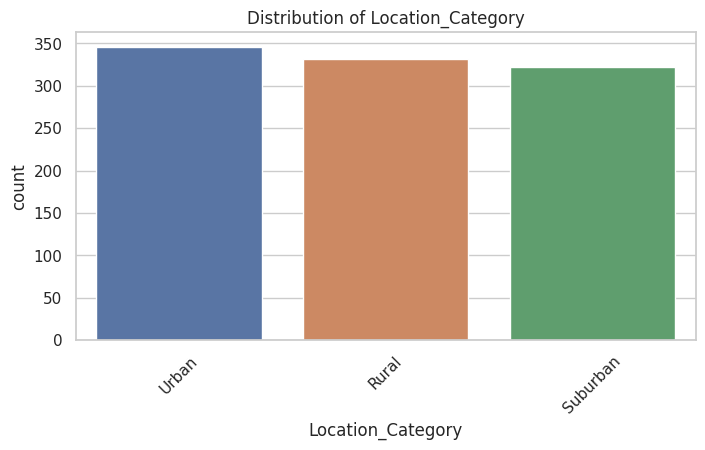

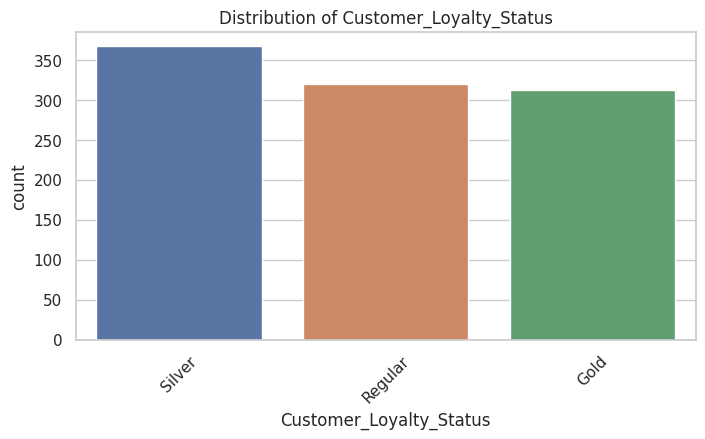

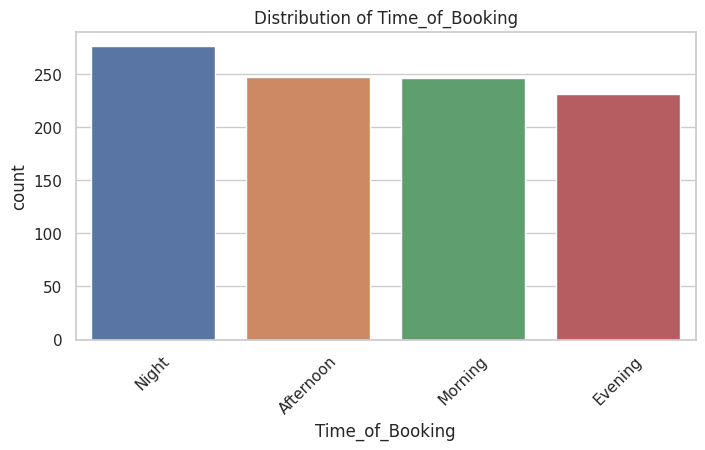

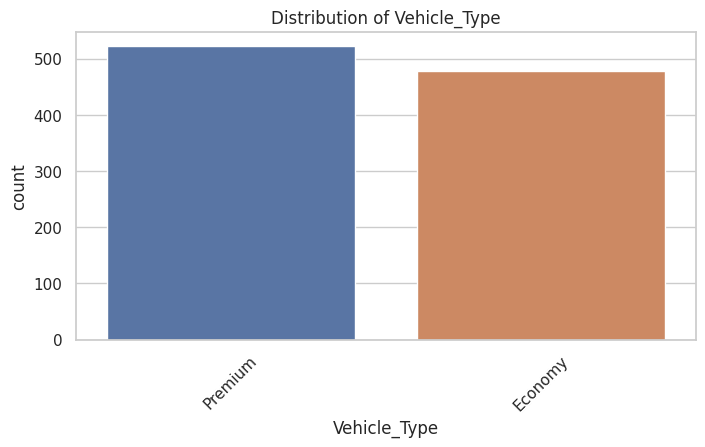

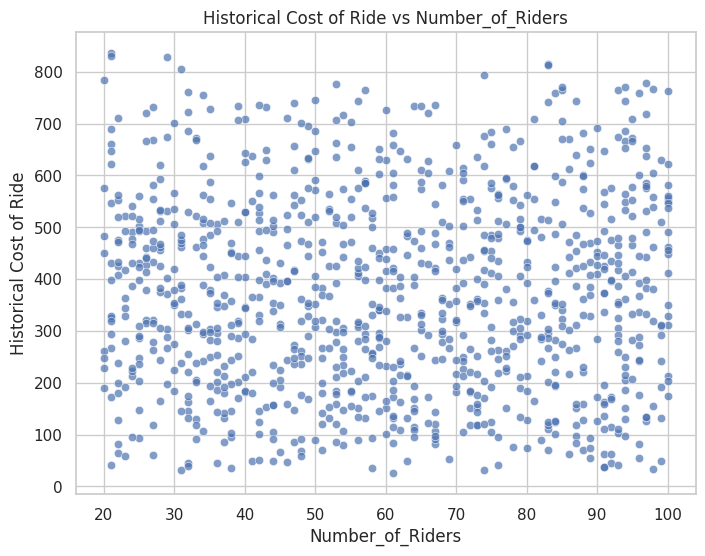

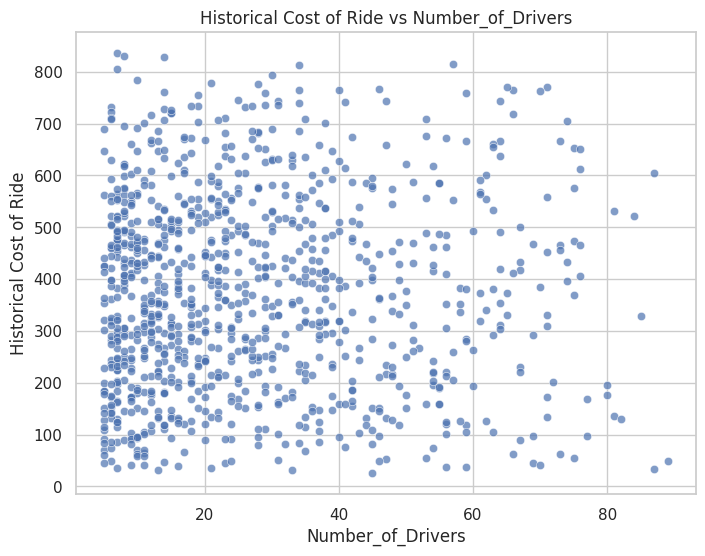

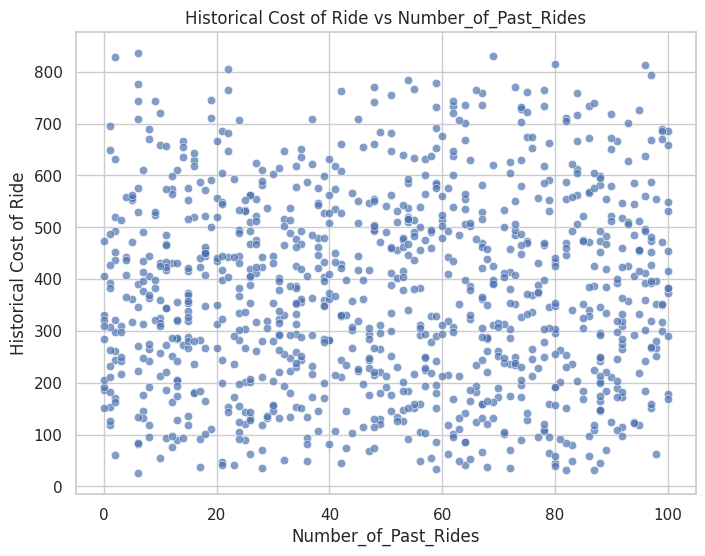

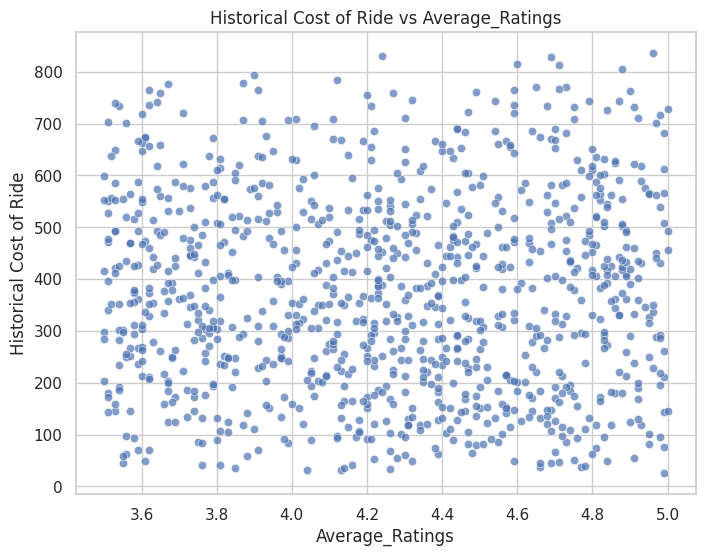

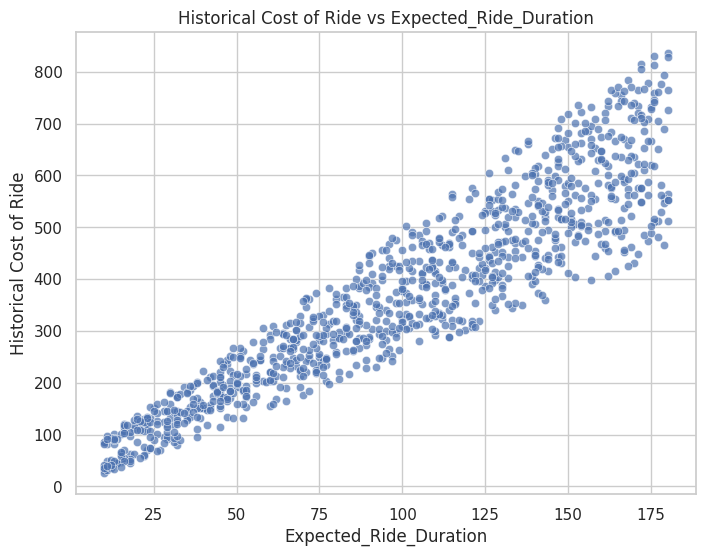

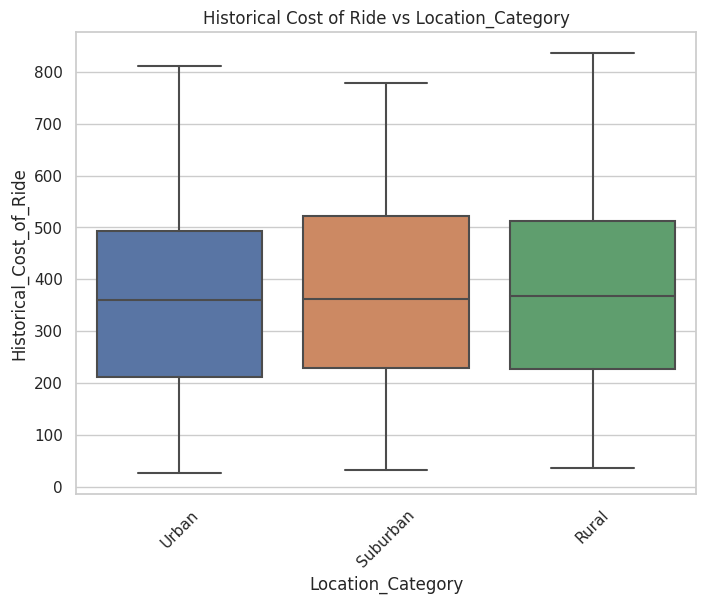

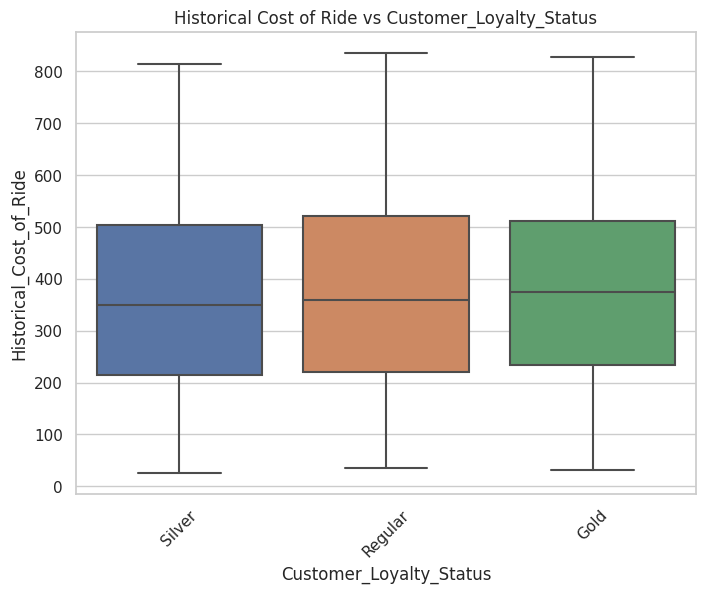

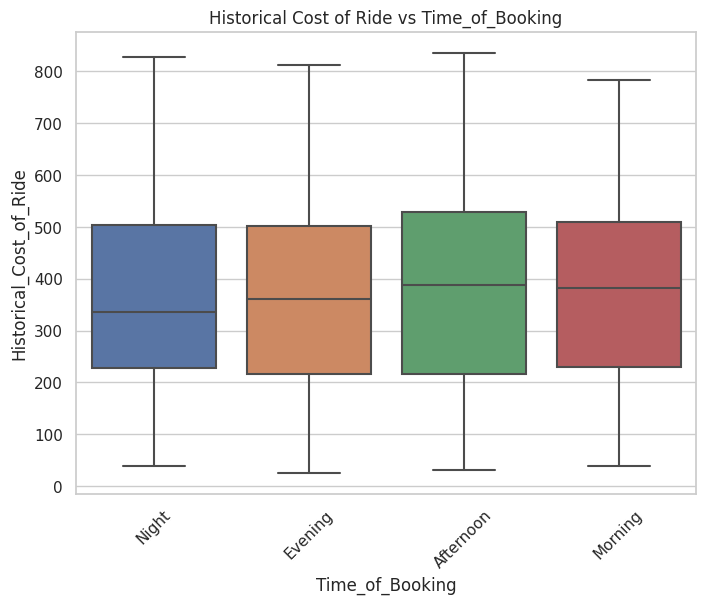

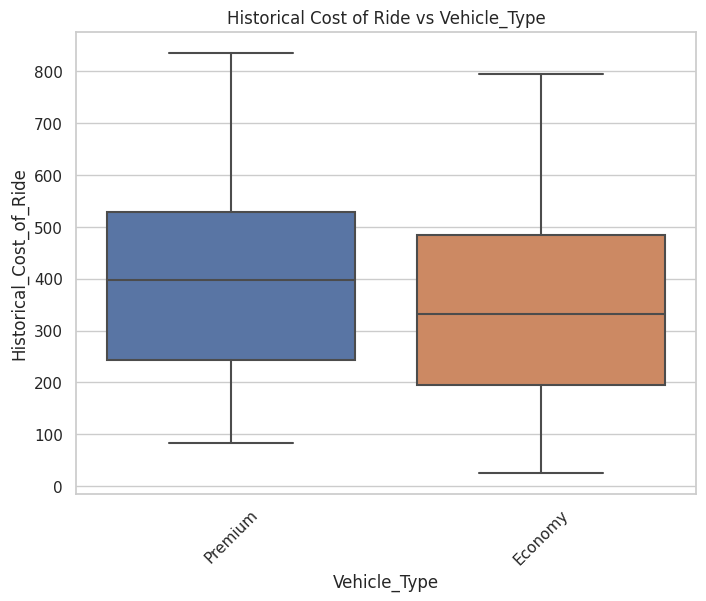

,Number_of_Riders,Number_of_Drivers,Number_of_Past_Rides,Average_Ratings,Expected_Ride_Duration,Historical_Cost_of_Ride
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000
mean,60.372000,27.076000,50.031000,4.257220,99.58800,372.502623
std,23.701506,19.068346,29.313774,0.435781,49.16545,187.158756
min,20.000000,5.000000,0.000000,3.500000,10.00000,25.993449
25%,40.000000,11.000000,25.000000,3.870000,59.75000,221.365202
50%,60.000000,22.000000,51.000000,4.270000,102.00000,362.019426
75%,81.000000,38.000000,75.000000,4.632500,143.00000,510.497504
max,100.000000,89.000000,100.000000,5.000000,180.00000,836.116419


In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set up the plotting environment
sns.set(style="whitegrid")

# Summary statistics of the dataset
summary_stats = df.describe()

# Distribution of numerical features
numerical_cols = ['Number_of_Riders', 'Number_of_Drivers', 'Number_of_Past_Rides', 
                  'Average_Ratings', 'Expected_Ride_Duration', 'Historical_Cost_of_Ride']

# Create histograms for numerical features
for col in numerical_cols:
    plt.figure(figsize=(8, 4))
    sns.histplot(df[col], kde=True, bins=30)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

# Visualize correlations between numerical features
plt.figure(figsize=(10, 6))
corr_matrix = df[numerical_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

# Categorical feature analysis
categorical_cols = ['Location_Category', 'Customer_Loyalty_Status', 
                    'Time_of_Booking', 'Vehicle_Type']

# Bar plots for categorical features
for col in categorical_cols:
    plt.figure(figsize=(8, 4))
    sns.countplot(data=df, x=col, order=df[col].value_counts().index)
    plt.title(f"Distribution of {col}")
    plt.xticks(rotation=45)
    plt.show()

# Relationship between Historical_Cost_of_Ride and other features
# Scatter plot for numerical relationships
for col in numerical_cols[:-1]:
    plt.figure(figsize=(8, 6))
    sns.scatterplot(data=df, x=col, y='Historical_Cost_of_Ride', alpha=0.7)
    plt.title(f"Historical Cost of Ride vs {col}")
    plt.xlabel(col)
    plt.ylabel("Historical Cost of Ride")
    plt.show()

# Box plots for categorical relationships
for col in categorical_cols:
    plt.figure(figsize=(8, 6))
    sns.boxplot(data=df, x=col, y='Historical_Cost_of_Ride')
    plt.title(f"Historical Cost of Ride vs {col}")
    plt.xticks(rotation=45)
    plt.show()

summary_stats


In [6]:
# Feature Engineering

# Calculate the driver-to-rider ratio
df['Driver_to_Rider_Ratio'] = df['Number_of_Drivers'] / df['Number_of_Riders']

# Create a feature for ride cost per minute

df['Cost_per_Minute'] = df['Historical_Cost_of_Ride'] / df['Expected_Ride_Duration']

# Encode categorical variables using one-hot encoding
encoded_df = pd.get_dummies(df, columns=['Location_Category', 'Customer_Loyalty_Status', 
                                         'Time_of_Booking', 'Vehicle_Type'], drop_first=True)

# Drop redundant columns if necessary
encoded_df = encoded_df.drop(columns=['Historical_Cost_of_Ride'])

# Display the first few rows of the engineered dataset
encoded_df.head()


,Number_of_Riders,Number_of_Drivers,Number_of_Past_Rides,Average_Ratings,Expected_Ride_Duration,Driver_to_Rider_Ratio,Cost_per_Minute,Location_Category_Suburban,Location_Category_Urban,Customer_Loyalty_Status_Regular,Customer_Loyalty_Status_Silver,Time_of_Booking_Evening,Time_of_Booking_Morning,Time_of_Booking_Night,Vehicle_Type_Premium
0,90,45,13,4.47,90,0.500000,3.158414,False,True,False,True,False,False,True,True
1,58,39,72,4.06,43,0.672414,4.043599,True,False,False,True,True,False,False,False
2,42,31,0,3.99,76,0.738095,4.339414,False,False,False,True,False,False,False,True
3,89,28,67,4.31,134,0.314607,3.508964,False,False,True,False,False,False,False,True
4,78,22,74,3.77,149,0.282051,3.890479,False,False,True,False,False,False,False,False


In [7]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Target variable
target = 'Historical_Cost_of_Ride'

# Features and target split
X = encoded_df
y = df[target]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Model initialization
model = RandomForestRegressor(random_state=42, n_estimators=100)

# Train the model
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

# Evaluate the model
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = mse ** 0.5
r2 = r2_score(y_test, y_pred)

mae, rmse, r2


(8.000863850807344, 10.65327636697776, 0.9968872792630441)

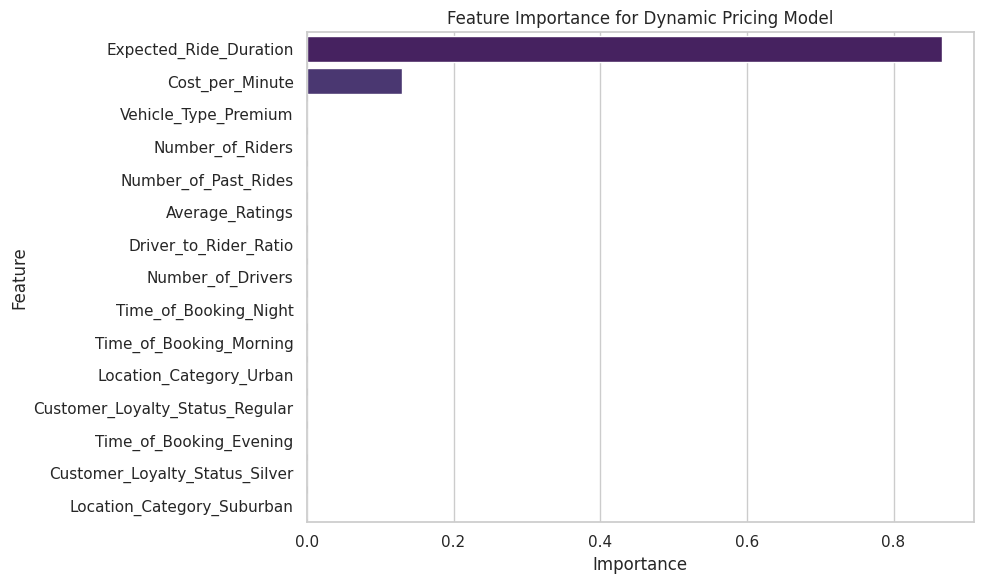

,Feature,Importance
4,Expected_Ride_Duration,0.866408
6,Cost_per_Minute,0.129141
14,Vehicle_Type_Premium,0.000777
0,Number_of_Riders,0.000691
2,Number_of_Past_Rides,0.000646
3,Average_Ratings,0.000599
5,Driver_to_Rider_Ratio,0.000560
1,Number_of_Drivers,0.000482
13,Time_of_Booking_Night,0.000127
12,Time_of_Booking_Morning,0.000114


In [8]:
# Extract feature importance
feature_importances = model.feature_importances_
importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': feature_importances
}).sort_values(by='Importance', ascending=False)

# Plot feature importance
plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df, x='Importance', y='Feature', palette='viridis')
plt.title('Feature Importance for Dynamic Pricing Model')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

importance_df


In [9]:
from sklearn.model_selection import GridSearchCV

# Define parameter grid for optimization
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Initialize GridSearchCV
grid_search = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=param_grid,
    cv=3,
    scoring='neg_mean_squared_error',
    n_jobs=-1,
    verbose=2
)

# Perform grid search
grid_search.fit(X_train, y_train)

# Best parameters and best score
best_params = grid_search.best_params_
best_score = -grid_search.best_score_  # Negative MSE to positive

best_params, best_score


Fitting 3 folds for each of 108 candidates, totalling 324 fits


({'max_depth': None,
  'min_samples_leaf': 1,
  'min_samples_split': 2,
  'n_estimators': 200},
 172.739009179282)

In [10]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Retrain the model using the best parameters
best_model = RandomForestRegressor(
    max_depth=None,
    min_samples_leaf=1,
    min_samples_split=2,
    n_estimators=200,
    random_state=42
)

# Train the model
best_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_best = best_model.predict(X_test)

# Evaluate the tuned model
mae_best = mean_absolute_error(y_test, y_pred_best)
mse_best = mean_squared_error(y_test, y_pred_best)
rmse_best = mse_best ** 0.5
r2_best = r2_score(y_test, y_pred_best)

mae_best, rmse_best, r2_best


(7.834169545210947, 10.414027261564533, 0.9970255190477505)

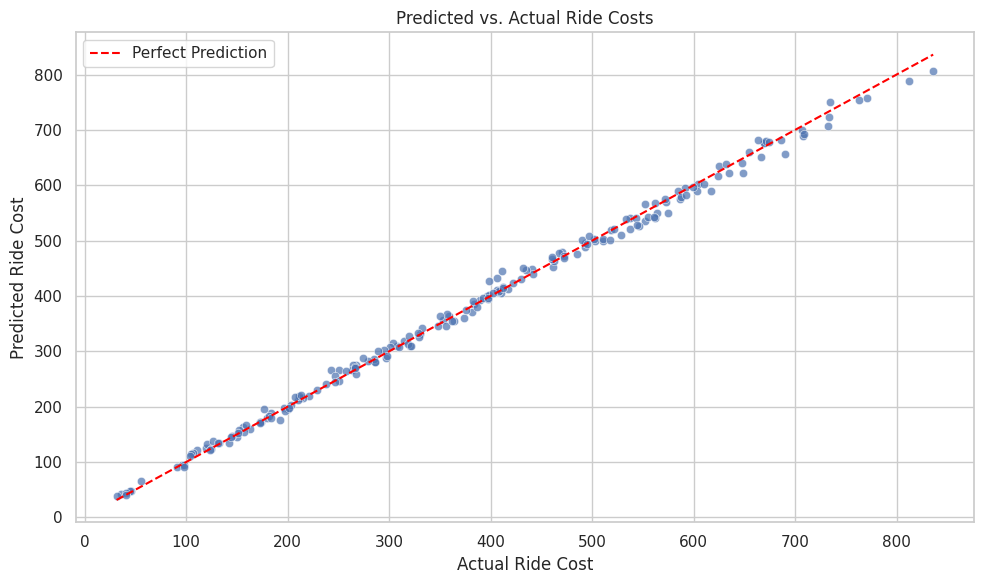

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot actual vs. predicted values
plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_test, y=y_pred_best, alpha=0.7)
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', linestyle='--', label='Perfect Prediction')
plt.title('Predicted vs. Actual Ride Costs')
plt.xlabel('Actual Ride Cost')
plt.ylabel('Predicted Ride Cost')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [12]:
import joblib

# Save the model
joblib.dump(best_model, 'dynamic_pricing_model.pkl')



['dynamic_pricing_model.pkl']